## 1 · NumPy — fast arrays & linear algebra

Create arrays, reshape them, and do real matrix math at native speed.


In [2]:
import numpy as np

arr = np.arange(1, 13).reshape(3, 4)
print('Array:'); print(arr)
print('\nShape:', arr.shape, '  Mean:', arr.mean(), '  Std: %.3f' % arr.std())
print('Column sums:', arr.sum(axis=0))
print('Matrix @ its transpose:'); print(arr @ arr.T)

Array:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Shape: (3, 4)   Mean: 6.5   Std: 3.452
Column sums: [15 18 21 24]
Matrix @ its transpose:
[[ 30  70 110]
 [ 70 174 278]
 [110 278 446]]


## 2 · Pandas — DataFrames & analysis

Load tabular data, add computed columns, filter and aggregate — the same API you use on your laptop.


In [3]:
import pandas as pd

df = pd.DataFrame({
    'city':   ['Tokyo', 'Delhi', 'Paris', 'Cairo', 'Lima'],
    'pop_m':  [37.4, 32.9, 11.2, 21.9, 10.7],
    'temp_c': [16, 25, 12, 22, 19],
})
df['density'] = (df['pop_m'] / df['temp_c']).round(2)
print('Warm cities (≥20°C):', list(df[df.temp_c >= 20]['city']))
df.sort_values('pop_m', ascending=False)

Warm cities (≥20°C): ['Delhi', 'Cairo']


,city,pop_m,temp_c,density
0,Tokyo,37.4,16,2.34
1,Delhi,32.9,25,1.32
3,Cairo,21.9,22,1.00
2,Paris,11.2,12,0.93
4,Lima,10.7,19,0.56


## 3 · Matplotlib — beautiful charts inline

Plot anything and see it rendered right inside the notebook.


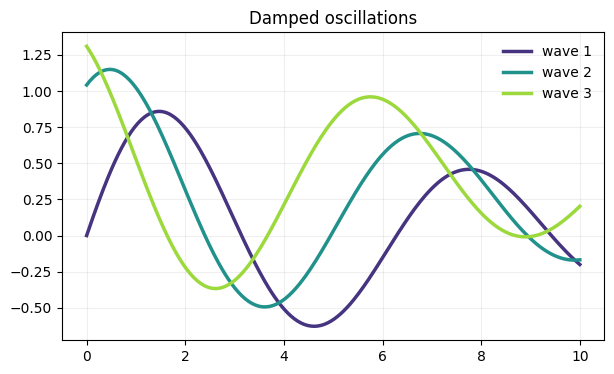

In [4]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib import cm

x = np.linspace(0, 10, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for i, c in enumerate(cm.viridis(np.linspace(0.15, 0.85, 3))):
    ax.plot(x, np.sin(x + i) * np.exp(-0.1 * x) + i*0.2, lw=2.5, color=c, label=f'wave {i+1}')
ax.set_title('Damped oscillations'); ax.legend(frameon=False); ax.grid(alpha=0.2)
plt.show()

## 4 · SciPy — scientific computing

Linear algebra, statistics, optimization, integration, interpolation and signal processing — the full **SciPy** stack, running natively on device. Tap **▶** to try it.


In [7]:
import numpy as np
from scipy import linalg, stats, optimize, integrate

# Linear algebra — solve  A·x = b
A = np.array([[3., 2.], [1., 4.]]);  b = np.array([7., 10.])
print('linalg.solve  →', linalg.solve(A, b))

# Statistics — standard-normal CDF and a one-sample t-test
print('P(Z < 1.96)   →', round(float(stats.norm.cdf(1.96)), 4))
t, p = stats.ttest_1samp([2.1, 2.4, 1.9, 2.3, 2.2], 2.0)
print('t-test        → t = %.3f,  p = %.3f' % (t, p))

# Optimization — minimize the classic Rosenbrock valley
rosen = lambda v: (1 - v[0])**2 + 100*(v[1] - v[0]**2)**2
print('minimize      →', optimize.minimize(rosen, [0, 0]).x.round(2))

# Integration —  ∫₀^∞ e^(-x²) dx  =  √π / 2
area, _ = integrate.quad(lambda x: np.exp(-x**2), 0, np.inf)
print('quad ∫e^(-x²) → %.6f   (√π/2 = %.6f)' % (area, np.sqrt(np.pi) / 2))

linalg.solve  → [0.8 2.3]
P(Z < 1.96)   → 0.975
t-test        → t = 2.092,  p = 0.105
minimize      → [1. 1.]
quad ∫e^(-x²) → 0.886227   (√π/2 = 0.886227)


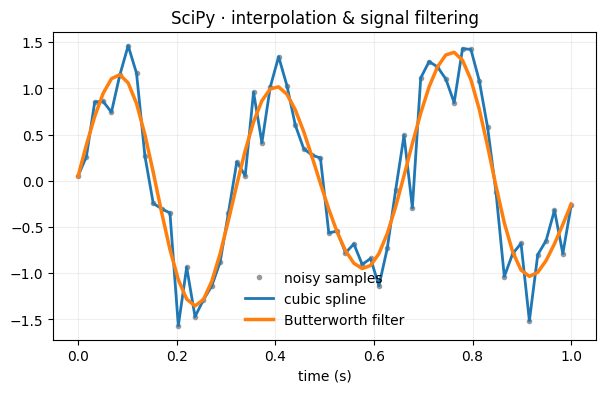

In [6]:
import numpy as np, matplotlib.pyplot as plt
from scipy import interpolate, signal

# A noisy 3 Hz signal — smooth it two ways with SciPy
rng = np.random.default_rng(0)
t = np.linspace(0, 1, 60)
noisy = np.sin(2*np.pi*3*t) + 0.4*rng.standard_normal(t.size)

spline   = interpolate.CubicSpline(t, noisy)      # cubic interpolation
b, a     = signal.butter(4, 0.2)                  # 4th-order low-pass
filtered = signal.filtfilt(b, a, noisy)           # zero-phase filter

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, noisy, '.', color='0.6', label='noisy samples')
ax.plot(t, spline(t), lw=2, label='cubic spline')
ax.plot(t, filtered, lw=2.5, label='Butterworth filter')
ax.set_title('SciPy · interpolation & signal filtering')
ax.set_xlabel('time (s)'); ax.legend(frameon=False); ax.grid(alpha=0.2)
plt.show()

## 5 · It's a real Jupyter notebook

- Write **Markdown**, tables, and LaTeX math like $E = mc^2$ and $\displaystyle\int_0^\infty e^{-x}\,dx = 1$
- Mix code and prose, run cells in any order
- Import & export standard `.ipynb` files

> **Your turn:** add a new cell with the **+** button and try `from scipy import optimize` — then build something amazing. 🚀
